# Campaign Response: Data Analysis and Prediction

## Data Science & AI/ML Practical — Set A

**Goal:** Explore customer campaign data, prepare it for modelling, and compare methods for predicting response.

**Input file:** `data/set_a.csv` (place `set_a.csv` inside the project's `data` folder)

### Work covered in this notebook
1. Descriptive statistics and hypothesis testing
2. Data cleaning and feature preparation
3. Classification with a baseline and Logistic Regression
4. Customer grouping with K-Means
5. A small Artificial Neural Network (ANN)

The sections follow the practical tasks in order, and the code saves the required tables, plots, and trained models.

In [6]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# Create folders used by the notebook's saved results.
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
Path("outputs/models").mkdir(parents=True, exist_ok=True)

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
rng = np.random.default_rng(404)
n = 300
cols = ['visits', 'recency', 'engagement', 'spend']
x = rng.normal(size=(n, 4))
group = rng.choice(["G1", "G2"], size=n)
score = x @ np.array([0.6, -0.9, 1.1, 0.4])
score += 0.4 * (group == "G2") + rng.normal(0, 1, n)
y = (score > 0).astype(int)
df = pd.DataFrame(np.round(50 + 10*x, 2), columns=cols)
df.insert(0, "record_id", np.arange(1, n+1))
df["group"] = group
df["response"] = y
for col in cols[:2]:
    df.loc[rng.choice(n, 15, replace=False), col] = np.nan
df = pd.concat([df, df.iloc[:5]], ignore_index=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/set_d.csv", index=False)


In [8]:
df = pd.read_csv("data/raw/set_d.csv")

df.head()

,record_id,visits,recency,engagement,spend,group,response
0,1,53.96,43.84,54.57,58.93,G2,1
1,2,NaN,49.75,52.97,63.64,G2,1
2,3,35.39,66.52,44.98,47.33,G2,0
3,4,45.01,42.80,47.62,54.48,G1,1
4,5,53.84,53.72,48.33,58.30,G2,1


In [9]:
row_count, column_count = df.shape

print(f"Rows: {row_count}")
print(f"Columns: {column_count}")
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values by column:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

Rows: 305
Columns: 7

Column names:
['record_id', 'visits', 'recency', 'engagement', 'spend', 'group', 'response']

Data types:
record_id       int64
visits        float64
recency       float64
engagement    float64
spend         float64
group          object
response        int64
dtype: object

Missing values by column:
record_id      0
visits        16
recency       15
engagement     0
spend          0
group          0
response       0
dtype: int64

Exact duplicate rows: 5


## Step 1 — Review the Data and Remove Duplicates

First, inspect the raw table and check its dimensions, column types, and missing values. The file contains 305 rows, including 5 exact duplicate rows.

We remove those duplicate rows in a separate cleaned DataFrame. The source CSV itself is left unchanged.

In [10]:
clean_df = df.drop_duplicates().copy()

print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)
print("Remaining duplicates:", clean_df.duplicated().sum())

Original shape: (305, 7)
Cleaned shape: (300, 7)
Remaining duplicates: 0


In [11]:
print("Unique record IDs:", clean_df["record_id"].nunique())

Unique record IDs: 300


## Step 2 — Create the Data Partitions

The cleaned records are split into three groups:
- **Fit set:** used to learn preprocessing settings and train models.
- **Validation set:** used to monitor ANN training.
- **Test set:** kept aside for the final evaluation.

The split is stratified by `response` so the target proportions are maintained as closely as possible. A fixed random state makes the split repeatable.

In [12]:
development_set, test = train_test_split(clean_df, test_size=0.20, stratify=clean_df["response"], random_state=42)

fit, validation = train_test_split(development_set, test_size=0.20, stratify=development_set["response"], random_state=42)

print("Fit:", fit.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Fit: (192, 7)
Validation: (48, 7)
Test: (60, 7)


In [13]:
partition_index = pd.concat([fit[["record_id"]].assign(partition="fit"),
                       validation[["record_id"]].assign(partition="validation"),
                       test[["record_id"]].assign(partition="test")], 
                      ignore_index=True)

partition_index.to_csv("outputs/splits.csv", index=False)

partition_index.head()

,record_id,partition
0,204,fit
1,123,fit
2,32,fit
3,289,fit
4,101,fit


In [14]:
# Verifying that partition IDs are unique and disjoint

print("Total partition IDs:", len(partition_index))
print("Unique partition IDs:", partition_index["record_id"].nunique())
print("Duplicate IDs:", partition_index["record_id"].duplicated().sum())

print("\nFit IDs:", fit["record_id"].nunique())
print("Validation IDs:", validation["record_id"].nunique())
print("Test IDs:", test["record_id"].nunique())

Total partition IDs: 300
Unique partition IDs: 300
Duplicate IDs: 0

Fit IDs: 192
Validation IDs: 48
Test IDs: 60


---

# Task 1 — Maths and Advanced Statistics

## M1 — Summarise Engagement

Use the fit partition to calculate descriptive statistics for `engagement`. For this task, calculate the measures from the observed values only; do not fill missing values first.

In [15]:
# Use available engagement values from the fit set
observed_engagement = fit["engagement"].dropna()

n_engagement = observed_engagement.count()
mean_engagement = observed_engagement.mean()
median_engagement = observed_engagement.median()
std_engagement = observed_engagement.std(ddof=1)

print("Observed n : ", n_engagement)
print("Mean : ", mean_engagement)
print("Median : ", median_engagement)
print("Sample Standard Deviation : ", std_engagement)


Observed n :  192
Mean :  51.00182291666667
Median :  51.405
Sample Standard Deviation :  10.288960500356747


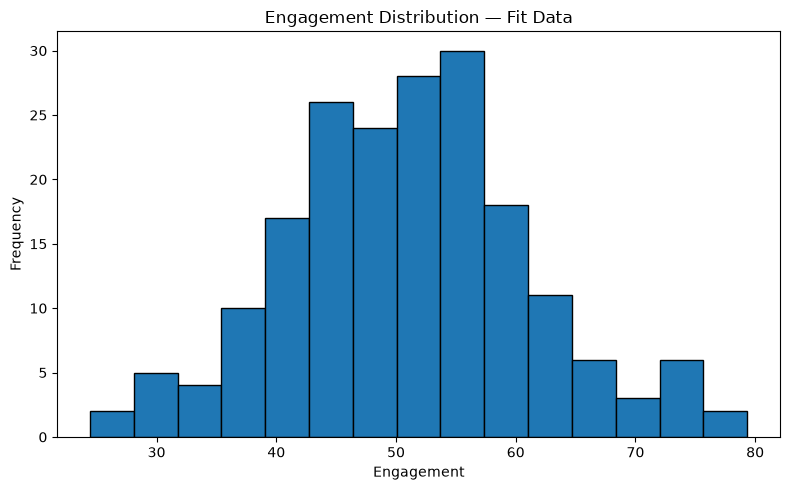

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(observed_engagement, bins=15, edgecolor="black")
plt.title("Engagement Distribution — Fit Data")
plt.xlabel("Engagement")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("outputs/figures/engagement_histogram.png", dpi=300)
plt.show()

**Interpretation:** The engagement values are mostly concentrated around 45–60, with a roughly bell-shaped distribution and a few higher values.

In [17]:
descriptive_summary = pd.DataFrame({"measure": ["observed_n", "mean", "median", "sample_std"],
                              "value": [n_engagement, mean_engagement, median_engagement, std_engagement]})

descriptive_summary.to_csv("outputs/statistics_summary.csv", index=False)
descriptive_summary

,measure,value
0,observed_n,192.000000
1,mean,51.001823
2,median,51.405000
3,sample_std,10.288961


**Interpretation:**

- The observed fit data contains 192 engagement values because `engagement` has no missing values.
- The mean and median are close, so the centre of the observed engagement values is around 51.
- The histogram shows the spread of engagement values in the fit partition.


## M2 — Test the Difference Between Groups

Compare the average `engagement` values for groups G1 and G2 with a two-sided Welch t-test. This version of the t-test does not assume that the two groups have equal variances.

- **Null hypothesis (H₀):** the group means are equal.
- **Alternative hypothesis (H₁):** the group means are different.

Use a significance level of 0.05 to interpret the p-value.

In [18]:
g1_engagement = fit.loc[fit["group"] == "G1", "engagement"].dropna()
g2_engagement = fit.loc[fit["group"] == "G2", "engagement"].dropna()

# Compare the two group means without assuming equal variances
t_stat, p_value = stats.ttest_ind(g1_engagement, g2_engagement, equal_var=False)

print("G1 count : ", len(g1_engagement))
print("G2 count : ", len(g2_engagement))
print("Welch t-statistic : ", t_stat)
print("p-value : ", p_value)

alpha = 0.05
if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

G1 count :  84
G2 count :  108
Welch t-statistic :  0.7229961865721685
p-value :  0.47065078178032727
Decision: Fail to reject H0


In [19]:
# 95% CI for overall observed mean engagement

n = len(observed_engagement)
mean = observed_engagement.mean()
std = observed_engagement.std(ddof=1)

standard_error = std / np.sqrt(n)

t_critical = stats.t.ppf(0.975, df=n - 1)

margin_error = t_critical * standard_error

ci_lower = mean - margin_error
ci_upper = mean + margin_error

print("95% Confidence Interval : ")
print(f"({ci_lower:.4f}, {ci_upper:.4f})")

95% Confidence Interval : 
(49.5372, 52.4665)


In [20]:
test_summary = pd.DataFrame({"item": ["G1 count", "G2 count", "Welch t-statistic", "p-value", "alpha", "CI lower", "CI upper"],
                                  "value": [len(g1_engagement), len(g2_engagement), t_stat, p_value, alpha, ci_lower, ci_upper]})

test_summary.to_csv("outputs/inference_results.csv", index=False)
test_summary

,item,value
0,G1 count,84.000000
1,G2 count,108.000000
2,Welch t-statistic,0.722996
3,p-value,0.470651
4,alpha,0.050000
5,CI lower,49.537188
6,CI upper,52.466458


**Interpretation:**

- The Welch t-test gives a p-value of approximately 0.471, which is greater than 0.05, so we fail to reject H₀.
- There is no statistically significant evidence of a difference in mean engagement between G1 and G2 in the fit data.
- The 95% confidence interval for the overall observed mean engagement is approximately 49.54 to 52.47.
- The test assumes independent observations and approximately normal sampling distributions.
- These results describe the synthetic observations and do not establish causation.


## M3 — Covariance Matrix and Eigenvalues

For records that have both `engagement` and `visits`, centre the two columns by subtracting their means. Use the centred values to calculate the sample covariance matrix.

Then calculate the matrix eigenvalues and eigenvectors. The largest eigenvalue corresponds to the direction with the greatest variance in these two features.

In [21]:
paired_data = fit[["engagement", "visits"]].dropna()

X = paired_data.to_numpy()

# Subtract each column mean to centre the data
X_mean = X.mean(axis=0)
centered_values = X - X_mean

print("Number of complete rows : ", len(X))
print("Column means : ", X_mean)
print("Centered matrix shape : ", centered_values.shape)

Number of complete rows :  181
Column means :  [51.08337017 49.4361326 ]
Centered matrix shape :  (181, 2)


In [22]:
# Sample covariance matrix
sample_covariance = (centered_values.T @ centered_values) / (len(centered_values) - 1)

print("Sample Covariance Matrix : ")
print(sample_covariance)

Sample Covariance Matrix : 
[[103.65708913   4.11811311]
 [  4.11811311 103.06117496]]


In [23]:
# Symmetric matrix eigenvalue calculation
eig_values, eig_vectors = np.linalg.eigh(sample_covariance)

# Sorting from largest to smallest
order = np.argsort(eig_values)[::-1]

eig_values = eig_values[order]
eig_vectors = eig_vectors[:, order]

largest_variance_share = eig_values[0] / eig_values.sum()

print("Eigenvalues : ", eig_values)
print("Largest eigenvalue : ", eig_values[0])
print("Largest variance share : ", largest_variance_share)
print("Largest variance share (%) : ", largest_variance_share * 100)

Eigenvalues :  [107.4880101   99.23025399]
Largest eigenvalue :  107.48801010083828
Largest variance share :  0.5199734555224486
Largest variance share (%) :  51.99734555224486


In [24]:
covariance_summary = pd.DataFrame(sample_covariance, index=["engagement", "visits"], columns=["engagement", "visits"])

covariance_summary.to_csv("outputs/covariance_matrix.csv")

eigenvalue_table = pd.DataFrame({"eigenvalue": eig_values, 
                                 "variance_share": eig_values / eig_values.sum()})

eigenvalue_table.to_csv("outputs/eigenvalues.csv", index=False)
eigenvalue_table

,eigenvalue,variance_share
0,107.488010,0.519973
1,99.230254,0.480027


**Interpretation:**

- The largest eigenvalue is approximately 107.49 and explains about 52.00% of the total variance.
- Its corresponding eigenvector represents the principal direction of greatest variation in the engagement and visits feature space.


---

# Task 2 — Data Preparation and Feature Engineering

## F1 — Check the Partitions

After removing the 5 duplicate rows, the dataset has 300 records. The expected partition sizes are:

- Fit: 192 records
- Validation: 48 records
- Test: 60 records

The code records each `record_id` and its partition in `outputs/splits.csv`, then checks that IDs are unique across the split.

In [25]:
numeric_features = ["visits", "recency", "engagement", "spend"]
categorical_features = ["group"]

target = "response"
id_column = "record_id"

# Separating predictors and target
X_fit = fit.drop(columns=[target, id_column]).copy()
X_val = validation.drop(columns=[target, id_column]).copy()
X_test = test.drop(columns=[target, id_column]).copy()

y_fit = fit[target].copy()
y_val = validation[target].copy()
y_test = test[target].copy()

print("Fit predictors : ", X_fit.shape)
print("Validation predictors : ", X_val.shape)
print("Test predictors : ", X_test.shape)

Fit predictors :  (192, 5)
Validation predictors :  (48, 5)
Test predictors :  (60, 5)


## F2 — Fill Missing Values, Encode, and Scale

Use median imputation for numeric columns. The medians must be learned from the fit set only, then reused for validation and test data.

Create the additional feature before scaling:

`engineered_feature = engagement / (recency + 1)`

Encode `group` with one-hot encoding. Standardise the numeric features using a scaler fitted on the fit set; keep the one-hot columns unscaled.

In [26]:
median_imputer = SimpleImputer(strategy="median")

# Learn imputation values from the fit partition only
X_fit_numeric_imputed = pd.DataFrame(median_imputer.fit_transform(X_fit[numeric_features]), columns=numeric_features, index=X_fit.index)

# Transform validation/test using the same fitted imputer
X_val_numeric_imputed = pd.DataFrame(median_imputer.transform(X_val[numeric_features]), columns=numeric_features, index=X_val.index)


X_test_numeric_imputed = pd.DataFrame(median_imputer.transform(X_test[numeric_features]), columns=numeric_features, index=X_test.index)

print("Fit medians : ")
print(pd.Series(median_imputer.statistics_, index=numeric_features))

Fit medians : 
visits        49.610
recency       50.600
engagement    51.405
spend         50.595
dtype: float64


In [27]:
# Add the new feature after filling missing values and before scaling

X_fit_numeric_imputed["engineered_feature"] = (X_fit_numeric_imputed["engagement"] / (X_fit_numeric_imputed["recency"] + 1))
X_val_numeric_imputed["engineered_feature"] = (X_val_numeric_imputed["engagement"] / (X_val_numeric_imputed["recency"] + 1))
X_test_numeric_imputed["engineered_feature"] = (X_test_numeric_imputed["engagement"] / (X_test_numeric_imputed["recency"] + 1))

print(X_fit_numeric_imputed.head())

     visits  recency  engagement  spend  engineered_feature
203   49.40    31.83       45.81  51.37            1.395370
122   48.59    49.00       48.49  33.13            0.969800
31    66.74    64.87       55.31  50.40            0.839684
288   41.41    43.90       48.08  42.13            1.070824
100   37.65    72.60       55.99  64.52            0.760734


In [28]:
from sklearn.preprocessing import OneHotEncoder

group_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

group_fit = group_encoder.fit_transform(X_fit[["group"]])
group_val = group_encoder.transform(X_val[["group"]])
group_test = group_encoder.transform(X_test[["group"]])

group_columns = group_encoder.get_feature_names_out(["group"])

group_fit = pd.DataFrame(group_fit, columns=group_columns, index=X_fit.index)
group_val = pd.DataFrame(group_val, columns=group_columns, index=X_val.index)
group_test = pd.DataFrame(group_test, columns=group_columns, index=X_test.index)

print("Encoded columns : ", list(group_columns))

Encoded columns :  ['group_G1', 'group_G2']


In [29]:
from sklearn.preprocessing import StandardScaler

# Numeric columns after feature engineering
numeric_features_final = ["visits", "recency", "engagement", "spend", "engineered_feature"]

feature_scaler = StandardScaler()

numeric_fit_scaled = feature_scaler.fit_transform(X_fit_numeric_imputed[numeric_features_final])
numeric_val_scaled = feature_scaler.transform(X_val_numeric_imputed[numeric_features_final])
numeric_test_scaled = feature_scaler.transform(X_test_numeric_imputed[numeric_features_final])

numeric_fit_scaled = pd.DataFrame(numeric_fit_scaled, columns=numeric_features_final, index=X_fit.index)
numeric_val_scaled = pd.DataFrame(numeric_val_scaled, columns=numeric_features_final, index=X_val.index)
numeric_test_scaled = pd.DataFrame(numeric_test_scaled, columns=numeric_features_final, index=X_test.index)

In [30]:
# Final transformed feature matrices
X_fit_final = pd.concat([numeric_fit_scaled, group_fit], axis=1)
X_val_final = pd.concat([numeric_val_scaled, group_val], axis=1)
X_test_final = pd.concat([numeric_test_scaled, group_test], axis=1)

print("Fit shape : ", X_fit_final.shape)
print("Validation shape : ", X_val_final.shape)
print("Test shape : ", X_test_final.shape)

print("\nFinal features : ")
print(X_fit_final.columns.tolist())

Fit shape :  (192, 7)
Validation shape :  (48, 7)
Test shape :  (60, 7)

Final features : 
['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']


## F3 — Validate the Prepared Features

Before modelling, check that the transformed partitions have matching columns and expected shapes. Also verify that the feature values are finite and that neither `response` nor `record_id` has been included as a predictor.

Save the fitted imputer, encoder, and scaler so the same transformations can be applied later without fitting them again.

In [31]:
# Check transformed shapes
print("Fit shape : ", X_fit_final.shape)
print("Validation shape : ", X_val_final.shape)
print("Test shape : ", X_test_final.shape)

# Check feature names
print("\nFeatures : ")
print(X_fit_final.columns.tolist())

# Check missing or infinite values
print("\nMissing values : ", X_fit_final.isnull().sum().sum())
print("Infinite values : ", np.isinf(X_fit_final.to_numpy()).sum())

# Check that target and ID are not included
print("\nTarget included : ", "response" in X_fit_final.columns)
print("Record ID included : ", "record_id" in X_fit_final.columns)

Fit shape :  (192, 7)
Validation shape :  (48, 7)
Test shape :  (60, 7)

Features : 
['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']

Missing values :  0
Infinite values :  0

Target included :  False
Record ID included :  False


In [32]:
# Save preprocessing audit
transform_audit = pd.DataFrame({
    "check": ["fit_rows", "validation_rows", "test_rows", "feature_count", "missing_values_fit", "infinite_values_fit", "target_in_features", "record_id_in_features"],
    "value": [len(X_fit_final), len(X_val_final), len(X_test_final), X_fit_final.shape[1], X_fit_final.isnull().sum().sum(), np.isinf(X_fit_final.to_numpy()).sum(), "response" in X_fit_final.columns, "record_id" in X_fit_final.columns]})

transform_audit.to_csv("outputs/preprocessing_audit.csv", index=False)
transform_audit

,check,value
0,fit_rows,192
1,validation_rows,48
2,test_rows,60
3,feature_count,7
4,missing_values_fit,0
5,infinite_values_fit,0
6,target_in_features,False
7,record_id_in_features,False


**Interpretation:**

- The transformed data contains 7 predictor features.
- There are no missing or infinite values in the transformed fit data.
- `response` and `record_id` are excluded from the model inputs.
- Imputation, encoding and scaling were fitted using the fit partition and then reused for validation and test data.


In [33]:
import joblib

saved_transformers = {"imputer": median_imputer,
                         "encoder": group_encoder,
                         "scaler": feature_scaler,
                         "numeric_features": numeric_features_final}

joblib.dump(saved_transformers, "outputs/models/preprocessing.joblib")
print("Preprocessing objects saved.")

Preprocessing objects saved.


---

# Task 3 — Supervised Classification

The target is `response`. Compare two approaches:

- A majority-class baseline, which predicts the most common class.
- Logistic Regression, which estimates the probability of a response.

Train both using the fit partition and evaluate them on the same untouched test partition of 60 records.

## S1 — Fit the Baseline and Logistic Regression

Start with a `DummyClassifier` using the most-frequent strategy to create a simple reference score. Then fit Logistic Regression, allowing up to 1,000 iterations for convergence.

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

target = "response"

X_train = X_fit_final
y_train = y_fit

# Establish a simple majority-class reference model
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

logreg_model = LogisticRegression(max_iter=1000)
logreg_model.fit(X_train, y_train)

print("Target : ", target)
print("Predictor features : ", X_train.columns.tolist())

print("\nPartition sizes : ")
print("Fit : ", len(X_fit_final))
print("Validation : ", len(X_val_final))
print("Test : ", len(X_test_final))

print("\nBaseline : ", baseline_model)
print("Logistic Regression : ", logreg_model)

Target :  response
Predictor features :  ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']

Partition sizes : 
Fit :  192
Validation :  48
Test :  60

Baseline :  DummyClassifier(strategy='most_frequent')
Logistic Regression :  LogisticRegression(max_iter=1000)


## S2 — Evaluate Classification Performance

Evaluate predictions for response class `1` on the held-out test set. Report accuracy, precision, recall, and F1-score. Logistic Regression probabilities are converted to class labels using a threshold of 0.5.

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_test_baseline = baseline_model.predict(X_test_final)
y_test_pred = logreg_model.predict(X_test_final)

# Class-1 probabilities
y_test_proba = logreg_model.predict_proba(X_test_final)[:, 1]

# Evaluation metrics
print("Baseline Accuracy : ", accuracy_score(y_test, y_test_baseline))
print("\nLogistic Regression Metrics : ")
print("Accuracy : ", accuracy_score(y_test, y_test_pred))
print("Precision : ", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall : ", recall_score(y_test, y_test_pred, zero_division=0))
print("F1-score : ", f1_score(y_test, y_test_pred, zero_division=0))

cm = confusion_matrix(y_test, y_test_pred)

print("\nConfusion Matrix : ")
print(cm)

Baseline Accuracy :  0.5833333333333334

Logistic Regression Metrics : 
Accuracy :  0.8166666666666667
Precision :  0.8333333333333334
Recall :  0.8571428571428571
F1-score :  0.8450704225352113

Confusion Matrix : 
[[19  6]
 [ 5 30]]


In [36]:
# Per-record test predictions
holdout_predictions = test[["record_id"]].copy()

holdout_predictions["true_label"] = y_test.values
holdout_predictions["predicted_label"] = y_test_pred
holdout_predictions["class_1_probability"] = y_test_proba

print(holdout_predictions.head(10))

     record_id  true_label  predicted_label  class_1_probability
253        254           1                1             0.999949
87          88           0                0             0.299585
121        122           0                0             0.059920
7            8           0                1             0.996980
196        197           0                1             0.647045
287        288           0                1             0.821099
129        130           1                1             0.744584
172        173           0                0             0.046317
177        178           1                1             0.965661
5            6           0                1             0.516976


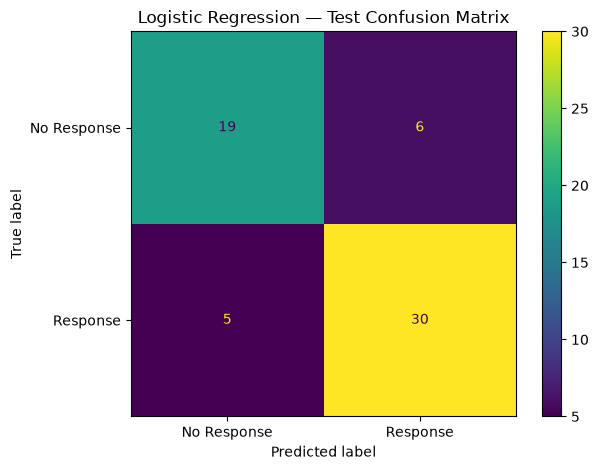

Classification threshold :  0.5
Undefined precision/recall values are handled using zero_division=0.


In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

threshold = 0.5

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Response", "Response"])

disp.plot()
plt.title("Logistic Regression — Test Confusion Matrix")
plt.tight_layout()

plt.savefig("outputs/figures/confusion_matrix.png", dpi=300)
plt.show()

print("Classification threshold : ", threshold)
print("Undefined precision/recall values are handled using zero_division=0.")

**Interpretation:** The model correctly identifies most responses, with 30 true positives and 19 true negatives. There are 6 false positives and 5 false negatives.

In [38]:
# Save supervised model results
model_metrics = pd.DataFrame({
    "model": ["Baseline", "Logistic Regression"],
    "accuracy": [accuracy_score(y_test, y_test_baseline), accuracy_score(y_test, y_test_pred)],
    "precision": [np.nan, precision_score(y_test, y_test_pred, zero_division=0)],
    "recall": [np.nan, recall_score(y_test, y_test_pred, zero_division=0)],
    "f1_score": [np.nan, f1_score(y_test, y_test_pred, zero_division=0)]})

model_metrics.to_csv("outputs/model_metrics.csv", index=False)
holdout_predictions.to_csv("outputs/test_predictions.csv", index=False)

print("Model metrics saved.")
print("Test predictions saved.")

model_metrics

Model metrics saved.
Test predictions saved.


,model,accuracy,precision,recall,f1_score
0,Baseline,0.583333,NaN,NaN,NaN
1,Logistic Regression,0.816667,0.833333,0.857143,0.84507


### S3 — Interpreting Classification Errors

- A **false negative** is a customer who would respond but is predicted not to respond; the campaign may miss a useful opportunity.
- A **false positive** is a customer predicted to respond who does not; campaign effort may be spent unnecessarily.

Compare Logistic Regression with the majority baseline using the test metrics. Since the test set contains only 60 records, treat the scores as estimates rather than guarantees of future performance.

---

# Task 4 — Unsupervised Learning with K-Means

Use K-Means to discover groups of customers with similar feature values. Fit the clustering model on the fit partition only, using the transformed numeric predictors and `engineered_feature`.

Do not include the one-hot `group` columns, the target `response`, or the identifier `record_id` in the clustering features.

## U1 — Select a Cluster Count

Test K-Means with `k` values of 2, 3, and 4. Each model uses `n_init=10` and `random_state=42` so the results are reproducible.

Compare silhouette scores and choose the value with the highest score. If scores tie, prefer the smaller number of clusters.

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ["visits", "recency", "engagement", "spend", "engineered_feature"]

X_cluster = X_fit_final[cluster_features].copy()

results = []

for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_cluster)
    inertia = model.inertia_
    silhouette = silhouette_score(X_cluster, labels)

    results.append({"k": k,
                    "inertia": inertia,
                    "silhouette_score": silhouette})

cluster_scores = pd.DataFrame(results)
cluster_scores

,k,inertia,silhouette_score
0,2,713.030410,0.225909
1,3,613.551097,0.187178
2,4,541.645319,0.190736


In [40]:
# Choose the cluster count with the best silhouette score
top_cluster_result = cluster_scores.sort_values(["silhouette_score", "k"], ascending=[False, True]).iloc[0]
chosen_k = int(top_cluster_result["k"])

print("Selected k : ", chosen_k)
print("Best silhouette score : ", top_cluster_result["silhouette_score"])

Selected k :  2
Best silhouette score :  0.22590949037480604


In [41]:
# Fit final K-Means using the selected k
final_clusterer = KMeans(n_clusters=chosen_k, n_init=10, random_state=42)

cluster_labels = final_clusterer.fit_predict(X_cluster)
clustered_fit = X_cluster.copy()
clustered_fit["cluster"] = cluster_labels

print("Selected k : ", chosen_k)
print("\nCluster counts : ")
print(clustered_fit["cluster"].value_counts().sort_index())

Selected k :  2

Cluster counts : 
cluster
0    109
1     83
Name: count, dtype: int64


In [42]:
cluster_scores.to_csv("outputs/kmeans_diagnostics.csv", index=False)
clustered_fit.to_csv("outputs/clustered_fit.csv", index=False)

print("K-Means diagnostics saved.")
print("Clustered fit data saved.")

K-Means diagnostics saved.
Clustered fit data saved.


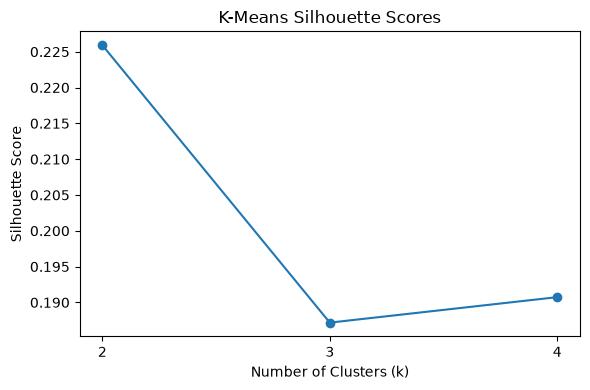

In [43]:
plt.figure(figsize=(6, 4))

plt.plot(cluster_scores["k"], cluster_scores["silhouette_score"], marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")
plt.xticks([2, 3, 4])

plt.tight_layout()
plt.savefig("outputs/figures/kmeans_silhouette.png", dpi=300)
plt.show()

**Interpretation:**

- K-Means was tested with k = 2, 3, and 4.
- The highest silhouette score is obtained with **k = 2**, so two audience segments are selected.
- The cluster selection is based only on the fit data and does not use the response target or test records.


## U2 — Summarise the Customer Segments

After choosing `k`, describe each cluster by calculating average values for the original-scale features. These summaries help explain how the groups differ.

Cluster numbers are only labels assigned by K-Means. They are not the same as the campaign response classes.

In [44]:
# Cluster profile using original-scale values
profile_values = X_fit_numeric_imputed.copy()
profile_values["cluster"] = cluster_labels

cluster_sizes = (profile_values["cluster"].value_counts().sort_index())

print("Cluster sizes : ")
print(cluster_sizes)

print("\nCluster profiles : ")
print(profile_values.groupby("cluster").mean().round(2))

Cluster sizes : 
cluster
0    109
1     83
Name: count, dtype: int64

Cluster profiles : 
         visits  recency  engagement  spend  engineered_feature
cluster                                                        
0         49.37    55.25       46.09  50.18                0.83
1         49.54    44.17       57.45  50.97                1.29


In [45]:
segment_summary = (profile_values.groupby("cluster").mean().round(2))
segment_summary["records"] = cluster_sizes
segment_summary.to_csv("outputs/cluster_profiles.csv")
segment_summary

,visits,recency,engagement,spend,engineered_feature,records
cluster,,,,,,
0,49.37,55.25,46.09,50.18,0.83,109
1,49.54,44.17,57.45,50.97,1.29,83


### U2 — Read the Cluster Profiles

#### Cluster 0 — Lower Engagement
- This segment has lower average engagement and a lower value for the engineered feature.
- **Possible action:** test a reminder or re-engagement message and measure the response.

#### Cluster 1 — Higher Engagement
- This segment has higher average engagement and a higher value for the engineered feature.
- **Possible action:** try relevant offers or follow-up communication.

These descriptions should be checked against the profile table. Cluster IDs are arbitrary and do not indicate whether a customer responded.

---

# Task 5 — Deep Learning: Artificial Neural Network

Build an ANN for the binary `response` target using the required layer layout:

`Input → Dense(16, ReLU) → Dense(8, ReLU) → Dense(1, Sigmoid)`

Use binary cross-entropy as the loss, Adam with learning rate `0.001`, batch size `16`, and a maximum of 50 epochs. Early stopping uses a patience of 5 epochs.

## D1 — Create the ANN

The network receives the prepared predictor columns as input. Two ReLU hidden layers learn patterns in the features, while the final sigmoid unit returns a probability between 0 and 1 for response class `1`.

In [46]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

tf.random.set_seed(42)
np.random.seed(42)

ann_model = Sequential([Dense(16, activation="relu", input_shape=(X_fit_final.shape[1],)),
                        Dense(8, activation="relu"),
                        Dense(1, activation="sigmoid")])

ann_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy",
                  metrics=["accuracy"])

ann_model.summary()

print("Trainable parameters : ", ann_model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters :  273


### D1 — Why These Settings Are Used

Because the target has two classes, binary cross-entropy is an appropriate loss function. Adam updates the model weights during training, and the sigmoid output can be interpreted as the estimated probability of a response.

## D2 — Train with Validation Monitoring

Train on the fit set for up to 50 epochs. During training, monitor loss on the separate validation set. Early stopping ends training if validation loss does not improve for 5 epochs and restores the weights from the best validation point.

In [47]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop if validation loss stops improving
stop_training = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

# Train the ANN
history = ann_model.fit(X_fit_final, y_fit, validation_data=(X_val_final, y_val), epochs=50, batch_size=16, callbacks=[stop_training], verbose=1)

print("Actual epochs : ", len(history.history["loss"]))

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4219 - loss: 0.7035 - val_accuracy: 0.4167 - val_loss: 0.6958
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4531 - loss: 0.6738 - val_accuracy: 0.4583 - val_loss: 0.6610
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5521 - loss: 0.6556 - val_accuracy: 0.5208 - val_loss: 0.6396
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6094 - loss: 0.6447 - val_accuracy: 0.5833 - val_loss: 0.6266
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6823 - loss: 0.6361 - val_accuracy: 0.6458 - val_loss: 0.6166
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7188 - loss: 0.6284 - val_accuracy: 0.6875 - val_loss: 0.6081
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7396 - loss: 0.6212 - val_accuracy: 0.7500 - val_loss: 0.6003
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7552 - loss: 0.6145 - val_accuracy: 0.7917 - val_loss

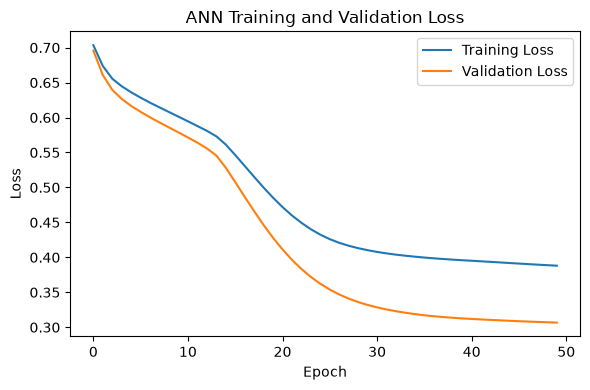

In [48]:
plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.savefig("outputs/figures/ann_loss_curve.png", dpi=300)
plt.show()

**Reading the loss plot:** Compare the training curve with the validation curve. A downward trend in both is consistent with learning; a widening gap or rising validation loss can indicate overfitting.

In [49]:
# Save ANN training information
training_summary = pd.DataFrame({"item": ["random_seed", "batch_size", "maximum_epochs", "patience", "actual_epochs", "best_validation_loss"],
                                  "value": [42, 16, 50, 5, len(history.history["loss"]), min(history.history["val_loss"])]})

training_summary.to_csv("outputs/ann_training_info.csv", index=False)
training_summary


,item,value
0,random_seed,42.00000
1,batch_size,16.00000
2,maximum_epochs,50.00000
3,patience,5.00000
4,actual_epochs,50.00000
5,best_validation_loss,0.30664


**What to check in the training record**

- Compare training loss with validation loss across epochs.
- If training loss continues to fall while validation loss rises, the network may be overfitting.
- Early stopping restores the weights associated with the best validation loss.

## D3 — Compare ANN and Logistic Regression

Evaluate the ANN on the same untouched test records. Convert its predicted probabilities to labels with a 0.5 threshold, then compare accuracy, precision, recall, and F1-score with Logistic Regression.

In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_test_proba_ann = ann_model.predict(X_test_final, verbose=0).ravel()

y_test_pred_ann = (y_test_proba_ann >= 0.5).astype(int)

# ANN metrics
ann_accuracy = accuracy_score(y_test, y_test_pred_ann)
ann_precision = precision_score(y_test, y_test_pred_ann, zero_division=0)
ann_recall = recall_score(y_test, y_test_pred_ann, zero_division=0)
ann_f1 = f1_score(y_test, y_test_pred_ann, zero_division=0)

print("ANN Test Metrics : ")
print("Accuracy : ", ann_accuracy)
print("Precision : ", ann_precision)
print("Recall : ", ann_recall)
print("F1-score : ", ann_f1)

ANN Test Metrics : 
Accuracy :  0.8166666666666667
Precision :  0.8157894736842105
Recall :  0.8857142857142857
F1-score :  0.8493150684931506


In [51]:
# Logistic Regression metrics
logreg_accuracy = accuracy_score(y_test, y_test_pred)
logreg_precision = precision_score(y_test, y_test_pred, zero_division=0)
logreg_recall = recall_score(y_test, y_test_pred, zero_division=0)
logreg_f1 = f1_score(y_test, y_test_pred, zero_division=0)

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "ANN"],
    "Accuracy": [logreg_accuracy, ann_accuracy],
    "Precision": [logreg_precision, ann_precision],
    "Recall": [logreg_recall, ann_recall],
    "F1-score": [logreg_f1, ann_f1]})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.816667,0.833333,0.857143,0.845070
1,ANN,0.816667,0.815789,0.885714,0.849315


In [52]:
# Save final model comparison
model_comparison.to_csv("outputs/final_model_comparison.csv", index=False)

# Save ANN predictions
ann_predictions = test[["record_id"]].copy()

ann_predictions["true_label"] = y_test.values
ann_predictions["predicted_label"] = y_test_pred_ann
ann_predictions["class_1_probability"] = y_test_proba_ann

ann_predictions.to_csv("outputs/ann_test_predictions.csv", index=False)

print("Final comparison saved.")
print("ANN predictions saved.")

Final comparison saved.
ANN predictions saved.


In [53]:
# Saving trained ANN
ann_model.save("outputs/models/ann_model.keras")

print("ANN model saved.")

ANN model saved.


### D3 — Explain the Comparison

Both models use the same test records and classification threshold, so their metrics can be compared directly. F1-score balances precision and recall for response class `1`. The model with the higher score is not automatically the best choice; also consider the full set of metrics and the simplicity of the model.

# Final Check — Required Outputs

The notebook includes all five practical modules. The final cell checks for the required result files, figures, and saved models.

### Tables and model files
- `outputs/splits.csv`
- `outputs/statistics_summary.csv`
- `outputs/inference_results.csv`
- `outputs/covariance_matrix.csv`
- `outputs/eigenvalues.csv`
- `outputs/preprocessing_audit.csv`
- `outputs/model_metrics.csv`
- `outputs/test_predictions.csv`
- `outputs/kmeans_diagnostics.csv`
- `outputs/cluster_profiles.csv`
- `outputs/final_model_comparison.csv`
- `outputs/ann_test_predictions.csv`
- `models/preprocessing.joblib`
- `models/ann_model.keras`

### Figures
- `outputs/figures/engagement_histogram.png`
- `outputs/figures/confusion_matrix.png`
- `outputs/figures/kmeans_silhouette.png`
- `outputs/figures/ann_loss_curve.png`

The raw input CSV and `generate_data.py` are not changed.

In [54]:
# Final file check
from pathlib import Path

required_files = [
    "outputs/splits.csv",
    "outputs/statistics_summary.csv",
    "outputs/inference_results.csv",
    "outputs/covariance_matrix.csv",
    "outputs/eigenvalues.csv",
    "outputs/preprocessing_audit.csv",
    "outputs/model_metrics.csv",
    "outputs/test_predictions.csv",
    "outputs/kmeans_diagnostics.csv",
    "outputs/cluster_profiles.csv",
    "outputs/final_model_comparison.csv",
    "outputs/ann_test_predictions.csv",
    "outputs/figures/engagement_histogram.png",
    "outputs/figures/confusion_matrix.png",
    "outputs/figures/kmeans_silhouette.png",
    "outputs/figures/ann_loss_curve.png",
    "outputs/models/preprocessing.joblib",
    "outputs/models/ann_model.keras"
]

for file in required_files:
    print("✓" if Path(file).exists() else "○", file)

✓ outputs/splits.csv
✓ outputs/statistics_summary.csv
✓ outputs/inference_results.csv
✓ outputs/covariance_matrix.csv
✓ outputs/eigenvalues.csv
✓ outputs/preprocessing_audit.csv
✓ outputs/model_metrics.csv
✓ outputs/test_predictions.csv
✓ outputs/kmeans_diagnostics.csv
✓ outputs/cluster_profiles.csv
✓ outputs/final_model_comparison.csv
✓ outputs/ann_test_predictions.csv
✓ outputs/figures/engagement_histogram.png
✓ outputs/figures/confusion_matrix.png
✓ outputs/figures/kmeans_silhouette.png
✓ outputs/figures/ann_loss_curve.png
✓ outputs/models/preprocessing.joblib
✓ outputs/models/ann_model.keras


---